# Project 1 – Age Detection (Klasifikasi Kelompok Usia dari Wajah)
Perbandingan 4 arsitektur Deep Learning: **AlexNet, VGG16, ResNet50, GoogLeNet (InceptionV3)**

**Dataset:** UTKFace (±23.700 foto wajah, label umur, gender, ras ada di nama file `[umur]_[gender]_[ras]_[tanggal].jpg`)

**Sebelum mulai:** aktifkan GPU → `Runtime > Change runtime type > T4 GPU`

Alur: Data Preparation → Data Splitting → Modelling & Hyperparameter Tuning → Evaluasi (Confusion Matrix) → Save Model → Demo (Upload Foto & Webcam)

## 1. Data Preparation
### 1.1 Load Library

In [ ]:
!pip -q install kagglehub
import os, glob, random, cv2
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.2 Download Dataset UTKFace
Dataset diunduh otomatis dari Kaggle (`jangedoo/utkface-new`). Jika diminta login, ikuti petunjuk yang muncul (butuh akun Kaggle gratis).
Alternatif: unggah `kaggle.json` lalu jalankan `!kaggle datasets download -d jangedoo/utkface-new -p /content --unzip`.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("jangedoo/utkface-new")
print("Dataset ada di:", path)

Using Colab cache for faster access to the 'utkface-new' dataset.
Dataset ada di: /kaggle/input/utkface-new


### 1.3 Load Gambar & Label Umur (dari nama file)

In [ ]:
files = glob.glob(os.path.join(path, '**', '*.jpg'), recursive=True)
rows = []
for f in files:
    parts = os.path.basename(f).split('_')
    if len(parts) >= 4:
        try:
            rows.append((f, os.path.basename(f), int(parts[0]), int(parts[1])))
        except ValueError:
            pass

df = pd.DataFrame(rows, columns=['path', 'name', 'age', 'gender'])
df = df.drop_duplicates('name')          # hindari file ganda (folder aligned vs crop_part)
df = df[(df.age >= 1) & (df.age <= 100)].reset_index(drop=True)
df['gender_name'] = df.gender.map({0: 'Male', 1: 'Female'})
print("Total gambar:", len(df))
df.head()

Total gambar: 23684


,path,name,age,gender,gender_name
0,/kaggle/input/utkface-new/UTKFace/26_0_2_20170...,26_0_2_20170104023102422.jpg.chip.jpg,26,0,Male
1,/kaggle/input/utkface-new/UTKFace/22_1_1_20170...,22_1_1_20170112233644761.jpg.chip.jpg,22,1,Female
2,/kaggle/input/utkface-new/UTKFace/21_1_3_20170...,21_1_3_20170105003215901.jpg.chip.jpg,21,1,Female
3,/kaggle/input/utkface-new/UTKFace/28_0_0_20170...,28_0_0_20170117180555824.jpg.chip.jpg,28,0,Male
4,/kaggle/input/utkface-new/UTKFace/17_1_4_20170...,17_1_4_20170103222931966.jpg.chip.jpg,17,1,Female


### 1.4 Membuat Kelompok Usia (Label Klasifikasi)

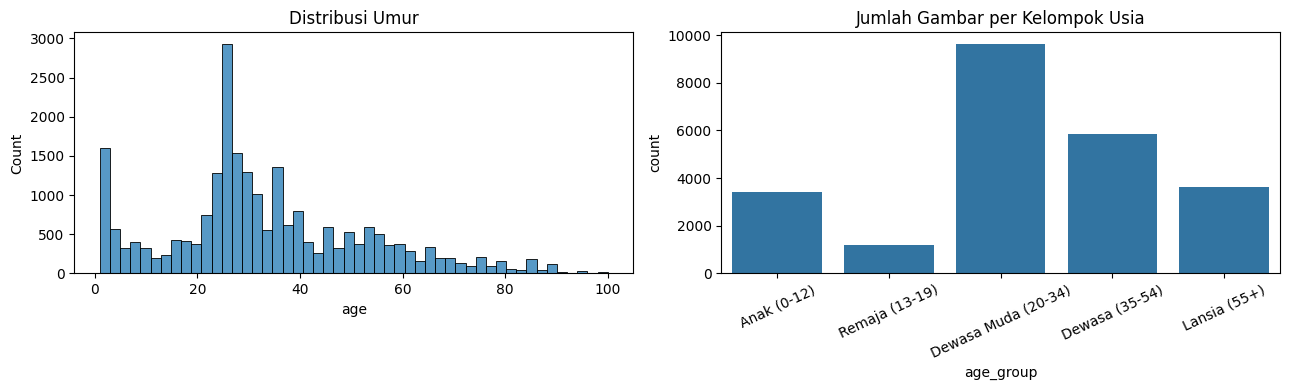

age_group
Anak (0-12)            3413
Remaja (13-19)         1180
Dewasa Muda (20-34)    9634
Dewasa (35-54)         5836
Lansia (55+)           3621
Name: count, dtype: int64


In [ ]:
bins   = [0, 12, 19, 34, 54, 200]
labels = ['Anak (0-12)', 'Remaja (13-19)', 'Dewasa Muda (20-34)', 'Dewasa (35-54)', 'Lansia (55+)']
df['age_group'] = pd.cut(df.age, bins=bins, labels=labels)
df['label'] = df.age_group.cat.codes
class_names = list(labels)
NUM_CLASSES = len(class_names)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.age, bins=50, ax=ax[0]); ax[0].set_title('Distribusi Umur')
sns.countplot(x='age_group', data=df, ax=ax[1]); ax[1].set_title('Jumlah Gambar per Kelompok Usia')
ax[1].tick_params(axis='x', rotation=25); plt.tight_layout(); plt.show()
print(df.age_group.value_counts().sort_index())

### 1.5 Menampilkan Contoh Gambar beserta Umur

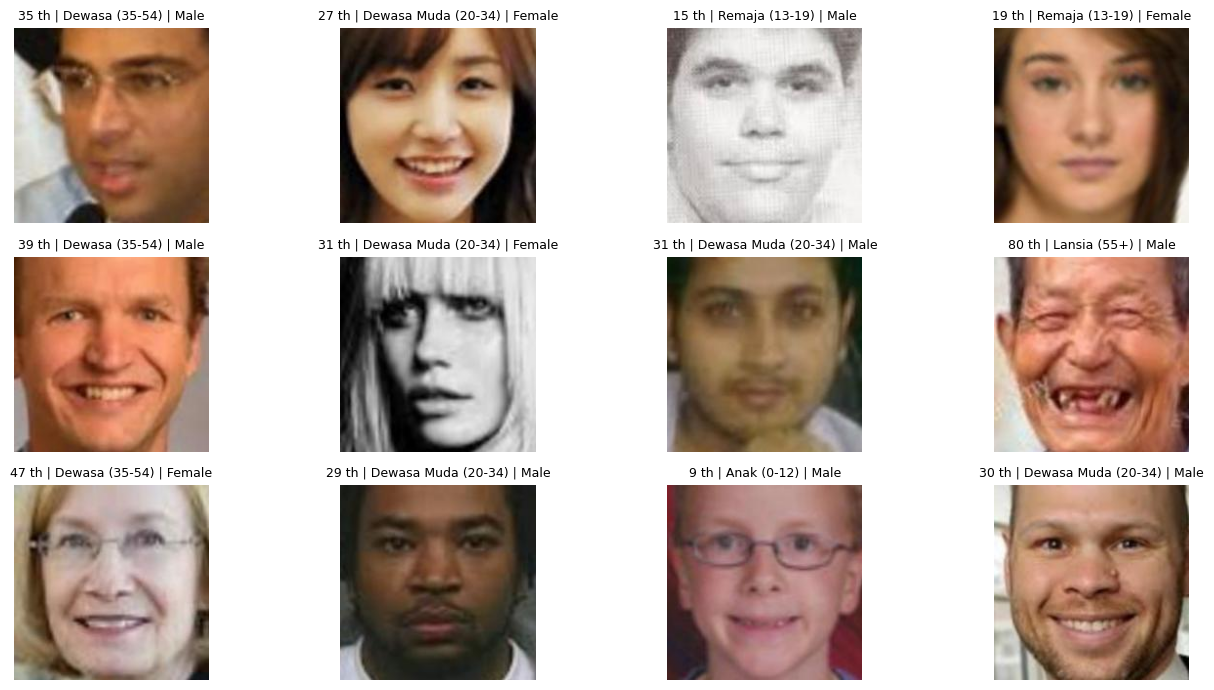

In [ ]:
sample = df.sample(12, random_state=SEED)
plt.figure(figsize=(14, 7))
for i, (_, r) in enumerate(sample.iterrows()):
    plt.subplot(3, 4, i + 1)
    plt.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
    plt.title(f"{r.age} th | {r.age_group} | {r.gender_name}", fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

### 1.6 Balancing Jumlah Gambar per Kelompok
Kelompok mayoritas dipotong (undersampling) hingga maksimal `CAP` gambar. Selain itu dipakai *class weight* saat training.

In [ ]:
CAP = 2000
df_bal = pd.concat([g.sample(min(len(g), CAP), random_state=SEED) for _, g in df.groupby('label')]).reset_index(drop=True)
print(df_bal.age_group.value_counts().sort_index())
print("Total setelah balancing:", len(df_bal))

age_group
Anak (0-12)            2000
Remaja (13-19)         1180
Dewasa Muda (20-34)    2000
Dewasa (35-54)         2000
Lansia (55+)           2000
Name: count, dtype: int64
Total setelah balancing: 9180


## 2. Data Splitting (Train 70% / Validation 15% / Test 15%)

In [ ]:
train_df, temp_df = train_test_split(df_bal, test_size=0.30, stratify=df_bal.label, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

IMG, BATCH = 128, 32
AUTOTUNE = tf.data.AUTOTUNE

def load_img(p, y):
    img = tf.io.read_file(p)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))      # float32, rentang 0-255
    return img, y

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values.astype('int32')))
    if train: ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

cw = compute_class_weight('balanced', classes=np.unique(train_df.label), y=train_df.label)
class_weight = dict(enumerate(cw)); print("Class weight:", class_weight)

Train: 6426 | Val: 1377 | Test: 1377
Class weight: {0: np.float64(0.918), 1: np.float64(1.5559322033898304), 2: np.float64(0.918), 3: np.float64(0.918), 4: np.float64(0.918)}


### 2.1 Data Augmentation
Augmentasi dijadikan layer di dalam model (hanya aktif saat training, otomatis nonaktif saat validasi/prediksi).

In [ ]:
def make_augment():
    return tf.keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name='augmentation')

## 3. Data Modelling
### 3.1 Arsitektur Model
- **AlexNet**: dibangun dari nol (5 Conv + 3 FC)
- **VGG16, ResNet50, GoogLeNet (InceptionV3)**: Transfer Learning (bobot ImageNet) + Fully Connected Layer baru

> Keras tidak menyediakan GoogLeNet (Inception-v1) bawaan, jadi dipakai **InceptionV3** (penerus GoogLeNet, sama-sama berbasis Inception module).

In [ ]:
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.applications import vgg16, resnet50, inception_v3

def build_alexnet(hp):
    inp = layers.Input((IMG, IMG, 3))
    x = make_augment()(inp)
    x = layers.Rescaling(1/255.)(x)
    x = layers.Conv2D(96, 11, strides=4, activation='relu')(x); x = layers.BatchNormalization()(x); x = layers.MaxPooling2D(3, 2)(x)
    x = layers.Conv2D(256, 5, padding='same', activation='relu')(x); x = layers.BatchNormalization()(x); x = layers.MaxPooling2D(3, 2)(x)
    x = layers.Conv2D(384, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(384, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(256, 3, padding='same', activation='relu')(x); x = layers.MaxPooling2D(3, 2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(hp['units'], activation='relu')(x); x = layers.Dropout(hp['dropout'])(x)
    x = layers.Dense(hp['units'], activation='relu')(x); x = layers.Dropout(hp['dropout'])(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return models.Model(inp, out, name='AlexNet'), None

TRANSFER = {
    'VGG16':       (VGG16,       vgg16.preprocess_input),
    'ResNet50':    (ResNet50,    resnet50.preprocess_input),
    'InceptionV3': (InceptionV3, inception_v3.preprocess_input),   # GoogLeNet family
}

def build_transfer(name, hp):
    Base, prep = TRANSFER[name]
    base = Base(include_top=False, weights='imagenet', input_shape=(IMG, IMG, 3))
    inp = layers.Input((IMG, IMG, 3))
    x = make_augment()(inp)
    x = layers.Lambda(prep, name='preprocess')(x)
    x = base(x, training=False)
    # Fully Connected Layer
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(hp['units'], activation='relu')(x)
    x = layers.Dropout(hp['dropout'])(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return models.Model(inp, out, name=name), base

def build_model(name, hp):
    return build_alexnet(hp) if name == 'AlexNet' else build_transfer(name, hp)

### 3.2 Hyperparameter, Compile & Training
Ubah nilai pada `HP` untuk melakukan tuning. Untuk transfer learning, training dilakukan 2 tahap: (1) latih head saja, (2) *fine-tuning* beberapa layer terakhir dengan learning rate lebih kecil.

In [ ]:
HP = {
    'AlexNet':     dict(lr=1e-3, dropout=0.5, units=512, epochs=30, finetune=False),
    'VGG16':       dict(lr=1e-3, dropout=0.5, units=256, epochs=10, finetune=True, ft_epochs=10, unfreeze=4),
    'ResNet50':    dict(lr=1e-3, dropout=0.4, units=256, epochs=10, finetune=True, ft_epochs=10, unfreeze=30),
    'InceptionV3': dict(lr=1e-3, dropout=0.4, units=256, epochs=10, finetune=True, ft_epochs=10, unfreeze=40),
}

def compile_model(model, lr):
    model.compile(optimizer=optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def get_callbacks():
    return [callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7)]

def train_model(name, hp, verbose=1):
    model, base = build_model(name, hp)
    if base is not None: base.trainable = False
    compile_model(model, hp['lr'])
    h = model.fit(train_ds, validation_data=val_ds, epochs=hp['epochs'],
                  callbacks=get_callbacks(), class_weight=class_weight, verbose=verbose)
    hist = {k: list(v) for k, v in h.history.items()}

    if base is not None and hp.get('finetune', False):
        base.trainable = True
        for l in base.layers[:-hp['unfreeze']]:
            l.trainable = False
        for l in base.layers:
            if isinstance(l, layers.BatchNormalization): l.trainable = False
        compile_model(model, hp['lr'] / 10)
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=hp['ft_epochs'],
                       callbacks=get_callbacks(), class_weight=class_weight, verbose=verbose)
        for k in hist: hist[k] += list(h2.history[k])
    return model, hist

def plot_curves(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist['accuracy'], label='train'); ax[0].plot(hist['val_accuracy'], label='val'); ax[0].set_title(f'{title} - Accuracy'); ax[0].legend()
    ax[1].plot(hist['loss'], label='train'); ax[1].plot(hist['val_loss'], label='val'); ax[1].set_title(f'{title} - Loss'); ax[1].legend()
    plt.show()

### 3.3 (Opsional) Grid Search Hyperparameter Sederhana
Contoh tuning cepat pada satu arsitektur (training singkat, tanpa fine-tuning). Hasil terbaik bisa dimasukkan ke `HP` di atas.

In [ ]:
import itertools
def quick_tuning(name, lrs=(1e-3, 3e-4), dropouts=(0.3, 0.5), units=(256, 512), epochs=3):
    res = []
    for lr, do, u in itertools.product(lrs, dropouts, units):
        hp = dict(lr=lr, dropout=do, units=u, epochs=epochs, finetune=False)
        m, h = train_model(name, hp, verbose=0)
        res.append(dict(lr=lr, dropout=do, units=u, val_acc=max(h['val_accuracy'])))
        print(res[-1])
    return pd.DataFrame(res).sort_values('val_acc', ascending=False)

# Jalankan jika ingin tuning (butuh waktu):
# quick_tuning('ResNet50')

### 3.4 Training Semua Model + Validation Curves


==================== Training AlexNet ====================
Epoch 1/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 31s 102ms/step - accuracy: 0.2913 - loss: 1.5949 - val_accuracy: 0.2607 - val_loss: 1.6073 - learning_rate: 0.0010
Epoch 2/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.3649 - loss: 1.4435 - val_accuracy: 0.2905 - val_loss: 1.5965 - learning_rate: 0.0010
Epoch 3/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.4052 - loss: 1.3526 - val_accuracy: 0.3696 - val_loss: 1.3558 - learning_rate: 0.0010
Epoch 4/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.4491 - loss: 1.2790 - val_accuracy: 0.3406 - val_loss: 1.5790 - learning_rate: 0.0010
Epoch 5/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.4525 - loss: 1.2448 - val_accuracy: 0.4386 - val_loss: 1.3148 - learning_rate: 0.0010
Epoch 6/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.4849 - loss: 1.2068 - val_accuracy: 0.2927 - val_loss: 2.0109 - learning_rate: 0.0010
Epoch 7/30
201/201 ━

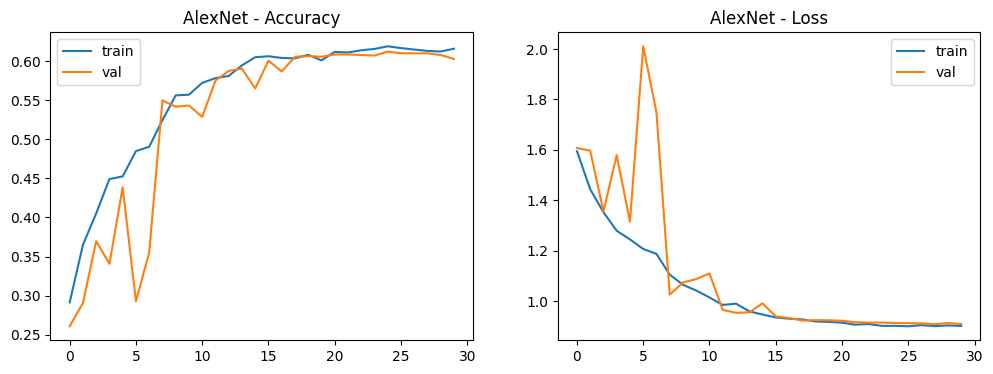


==================== Training VGG16 ====================
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 71ms/step - accuracy: 0.4535 - loss: 2.0865 - val_accuracy: 0.5221 - val_loss: 1.0878 - learning_rate: 0.0010
Epoch 2/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - accuracy: 0.5095 - loss: 1.1408 - val_accuracy: 0.5599 - val_loss: 1.0369 - learning_rate: 0.0010
Epoch 3/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 67ms/step - accuracy: 0.5405 - loss: 1.0945 - val_accuracy: 0.5904 - val_loss: 0.9794 - learning_rate: 0.0010
Epoch 4/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.5650 - loss: 1.0402 - val_accuracy: 0.5999 - val_loss: 0.9757 - learning_rate: 0.0010
Epoch 5/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 13s 65ms/step - accuracy: 0.5616 - loss: 1.0250 - val_accuracy: 0.5853 - val_loss: 0.9820 - learning_rate: 0.0010
Epoch 6/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.5820 - loss: 0.9991 - val_accuracy: 0.5853 - val_loss

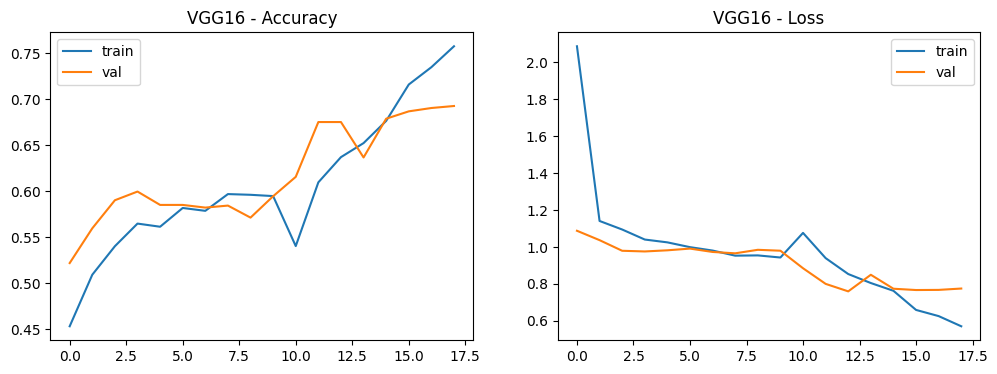


==================== Training ResNet50 ====================
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 24s 85ms/step - accuracy: 0.5227 - loss: 1.1702 - val_accuracy: 0.5701 - val_loss: 0.9735 - learning_rate: 0.0010
Epoch 2/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 18s 90ms/step - accuracy: 0.5864 - loss: 0.9990 - val_accuracy: 0.5933 - val_loss: 0.9368 - learning_rate: 0.0010
Epoch 3/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 70ms/step - accuracy: 0.5955 - loss: 0.9642 - val_accuracy: 0.5940 - val_loss: 0.9110 - learning_rate: 0.0010
Epoch 4/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - accuracy: 0.6058 - loss: 0.9399 - val_accuracy: 0.6028 - val_loss: 0.9037 - learning_rate: 0.0010
Epoch 5/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - accuracy: 0.6144 - loss: 0.9197 - val_accuracy: 0.6129 - val_loss: 0.8788 - learning_rate: 0.0010
Epoch 6/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - accuracy: 0.6251 - loss: 0.8909 - val_accuracy: 0.6369 - val_l

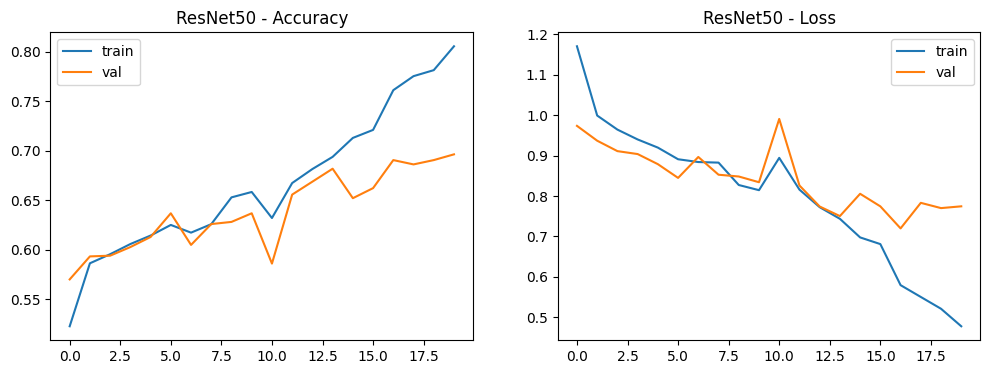


==================== Training InceptionV3 ====================
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 22s 73ms/step - accuracy: 0.5016 - loss: 1.2717 - val_accuracy: 0.5476 - val_loss: 1.0504 - learning_rate: 0.0010
Epoch 2/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.5336 - loss: 1.1081 - val_accuracy: 0.5679 - val_loss: 1.0018 - learning_rate: 0.0010
Epoch 3/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.5417 - loss: 1.0863 - val_accuracy: 0.5599 - val_loss: 1.0149 - learning_rate: 0.0010
Epoch 4/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.5470 - loss: 1.0594 - val_accuracy: 0.5904 - val_loss: 0.9632 - learning_rate: 0.0010
Epoch 5/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.5557 - loss: 1.0469 - val_accuracy: 0.5904 - val_loss: 0.9665 - learning_rate: 0.0010
Epoch 6/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.5548 - loss: 1.0488 - val_accuracy: 0.5723 - va

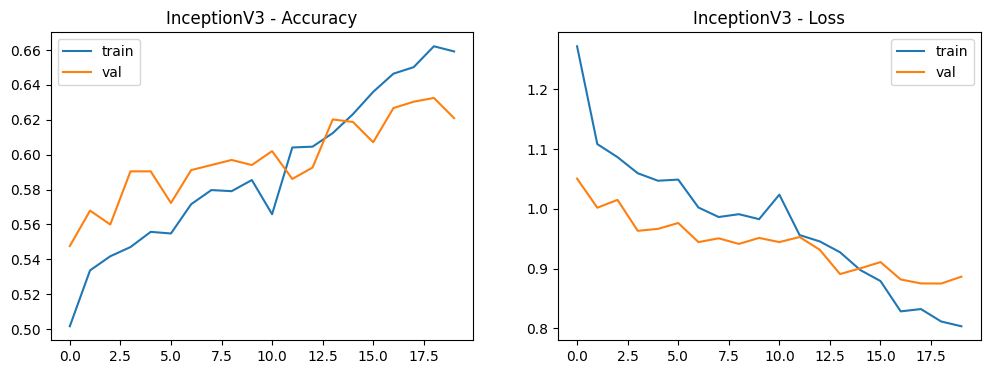

In [ ]:
trained, histories = {}, {}
for name in ['AlexNet', 'VGG16', 'ResNet50', 'InceptionV3']:
    print(f"\n{'='*20} Training {name} {'='*20}")
    trained[name], histories[name] = train_model(name, HP[name])
    plot_curves(histories[name], name)

## 4. Prediction & Testing
### 4.1 Evaluasi pada Data Test (Confusion Matrix & Metrik)
Selain akurasi dan F1, dihitung juga **akurasi ±1 kelompok** (prediksi benar atau meleset satu kelompok usia terdekat), karena batas antar kelompok umur sifatnya tidak tegas.


===== AlexNet =====
                     precision    recall  f1-score   support

        Anak (0-12)      0.886     0.830     0.857       300
     Remaja (13-19)      0.419     0.537     0.470       177
Dewasa Muda (20-34)      0.580     0.533     0.556       300
     Dewasa (35-54)      0.533     0.460     0.494       300
       Lansia (55+)      0.671     0.747     0.707       300

           accuracy                          0.629      1377
          macro avg      0.618     0.621     0.617      1377
       weighted avg      0.635     0.629     0.630      1377



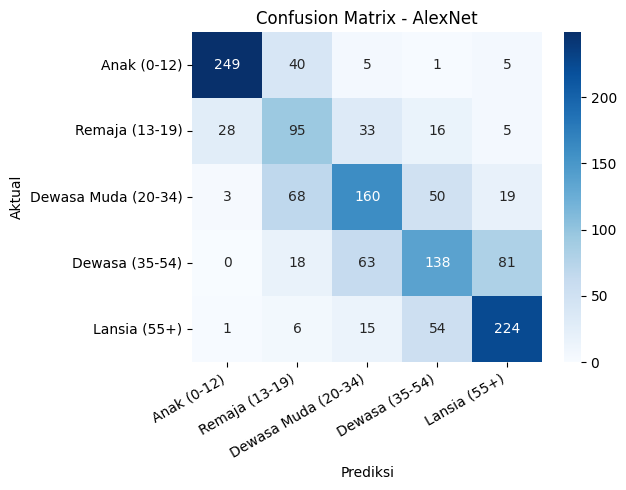


===== VGG16 =====
                     precision    recall  f1-score   support

        Anak (0-12)      0.869     0.910     0.889       300
     Remaja (13-19)      0.560     0.475     0.514       177
Dewasa Muda (20-34)      0.554     0.763     0.642       300
     Dewasa (35-54)      0.573     0.500     0.534       300
       Lansia (55+)      0.836     0.663     0.740       300

           accuracy                          0.679      1377
          macro avg      0.679     0.662     0.664      1377
       weighted avg      0.689     0.679     0.677      1377



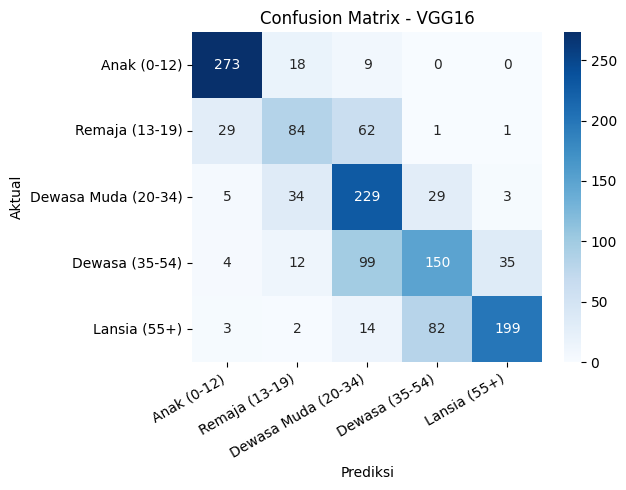


===== ResNet50 =====
                     precision    recall  f1-score   support

        Anak (0-12)      0.908     0.890     0.899       300
     Remaja (13-19)      0.565     0.565     0.565       177
Dewasa Muda (20-34)      0.624     0.670     0.646       300
     Dewasa (35-54)      0.547     0.583     0.565       300
       Lansia (55+)      0.818     0.720     0.766       300

           accuracy                          0.696      1377
          macro avg      0.692     0.686     0.688      1377
       weighted avg      0.704     0.696     0.699      1377



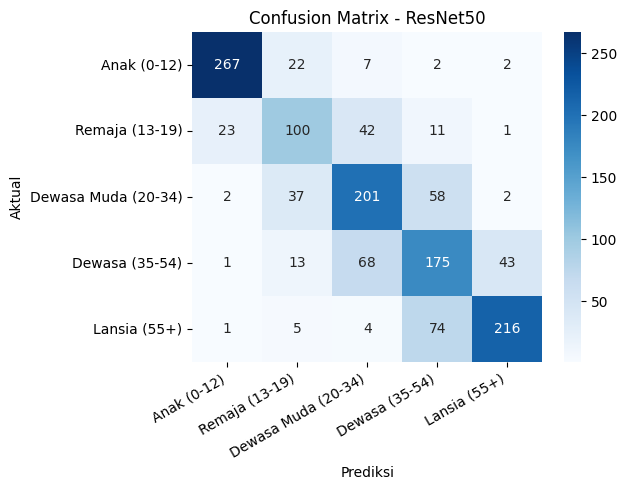


===== InceptionV3 =====
                     precision    recall  f1-score   support

        Anak (0-12)      0.909     0.770     0.834       300
     Remaja (13-19)      0.470     0.616     0.533       177
Dewasa Muda (20-34)      0.601     0.517     0.556       300
     Dewasa (35-54)      0.457     0.490     0.473       300
       Lansia (55+)      0.707     0.733     0.720       300

           accuracy                          0.626      1377
          macro avg      0.629     0.625     0.623      1377
       weighted avg      0.643     0.626     0.631      1377



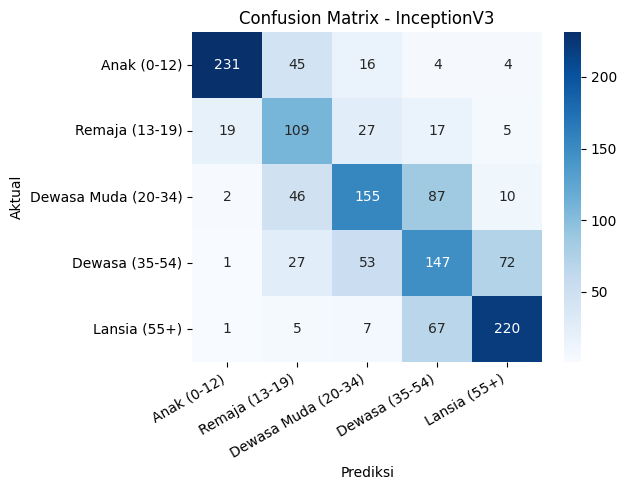

In [ ]:
y_true = test_df.label.values
results, preds = {}, {}

for name, model in trained.items():
    prob = model.predict(test_ds, verbose=0)
    y_pred = prob.argmax(1); preds[name] = y_pred
    results[name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1-macro': f1_score(y_true, y_pred, average='macro'),
        'Acc ±1 kelompok': np.mean(np.abs(y_pred - y_true) <= 1),
    }
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6.5, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {name}'); plt.xlabel('Prediksi'); plt.ylabel('Aktual')
    plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

### 4.2 Perbandingan Kinerja Arsitektur

,Accuracy,F1-macro,Acc ±1 kelompok
ResNet50,0.6964,0.6881,0.9630
VGG16,0.6790,0.6638,0.9608
InceptionV3,0.6260,0.6231,0.9281
AlexNet,0.6289,0.6167,0.9317


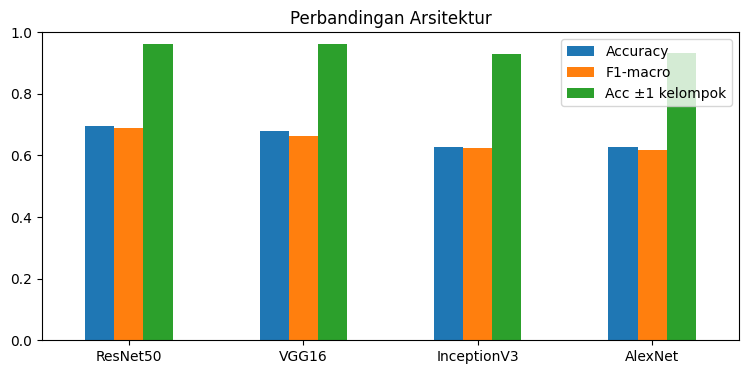

Model terbaik: ResNet50


In [ ]:
res_df = pd.DataFrame(results).T.sort_values('F1-macro', ascending=False).round(4)
display(res_df)
res_df[['Accuracy', 'F1-macro', 'Acc ±1 kelompok']].plot(kind='bar', figsize=(9, 4), rot=0)
plt.title('Perbandingan Arsitektur'); plt.ylim(0, 1); plt.show()

best_name = res_df.index[0]
best_model = trained[best_name]
print("Model terbaik:", best_name)

### 4.3 Foto Aktual vs Prediksi & Foto yang Salah Prediksi (model terbaik)

,name,age,aktual,pred
0,58_0_3_20170119211542128.jpg.chip.jpg,58,Lansia (55+),Lansia (55+)
1,43_0_0_20170104210618508.jpg.chip.jpg,43,Dewasa (35-54),Dewasa (35-54)
2,14_1_0_20170109212518607.jpg.chip.jpg,14,Remaja (13-19),Remaja (13-19)
3,2_1_0_20170109191147581.jpg.chip.jpg,2,Anak (0-12),Anak (0-12)
4,24_1_0_20170103180549431.jpg.chip.jpg,24,Dewasa Muda (20-34),Dewasa Muda (20-34)
5,58_0_1_20170117184831471.jpg.chip.jpg,58,Lansia (55+),Lansia (55+)
6,8_1_0_20170109202434032.jpg.chip.jpg,8,Anak (0-12),Remaja (13-19)
7,1_1_0_20170109191709485.jpg.chip.jpg,1,Anak (0-12),Anak (0-12)
8,2_1_0_20170109190516025.jpg.chip.jpg,2,Anak (0-12),Anak (0-12)
9,41_0_3_20170104215454077.jpg.chip.jpg,41,Dewasa (35-54),Dewasa (35-54)


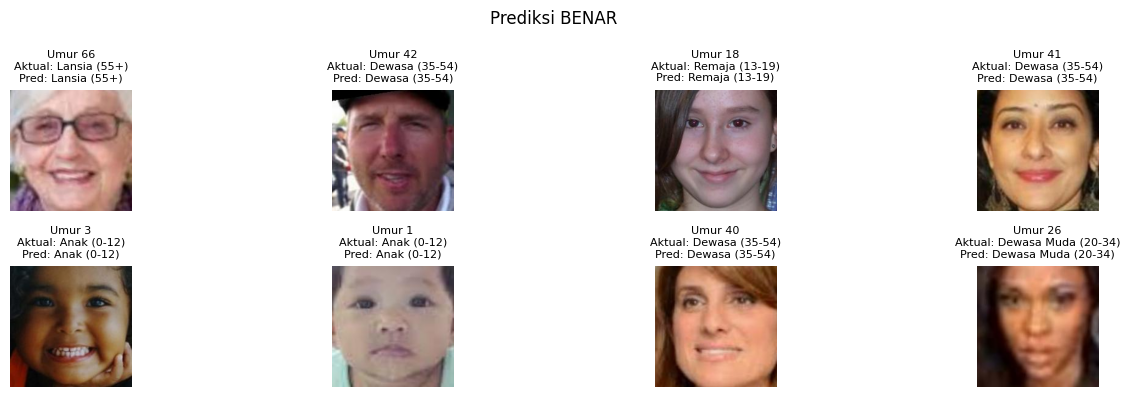

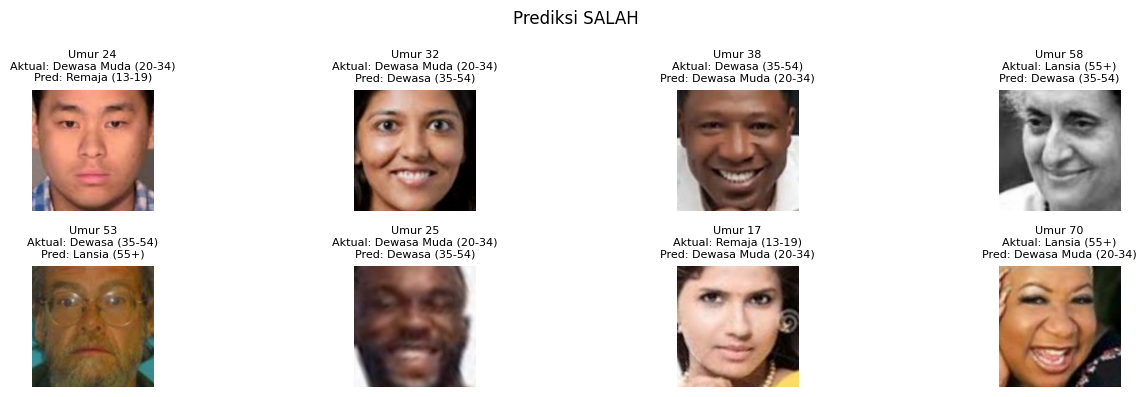

In [ ]:
best_pred = preds[best_name]
out = test_df.copy().reset_index(drop=True)
out['pred'] = [class_names[i] for i in best_pred]
out['aktual'] = [class_names[i] for i in y_true]
display(out[['name', 'age', 'aktual', 'pred']].head(10))

def show(d, title, n=8):
    d = d.head(n)
    plt.figure(figsize=(14, 4))
    for i, (_, r) in enumerate(d.iterrows()):
        plt.subplot(2, 4, i + 1)
        plt.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
        plt.title(f"Umur {r.age}\nAktual: {r.aktual}\nPred: {r.pred}", fontsize=8); plt.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.show()

show(out[out.aktual == out.pred].sample(8, random_state=SEED), "Prediksi BENAR")
show(out[out.aktual != out.pred].sample(8, random_state=SEED), "Prediksi SALAH")

## 5. Save Model

In [ ]:
for name, model in trained.items():
    model.save(f'/content/age_{name}.keras')
print("Tersimpan di /content/ :", [f for f in os.listdir('/content') if f.endswith('.keras')])

# (Opsional) simpan ke Google Drive
# from google.colab import drive; drive.mount('/content/drive')
# !cp /content/age_*.keras /content/drive/MyDrive/

Tersimpan di /content/ : ['age_VGG16.keras', 'age_ResNet50.keras', 'age_InceptionV3.keras', 'age_AlexNet.keras']


## 6. Demo Hasil Akhir
### 6.1 Upload Foto → Muncul Prediksi Kelompok Usia

Saving WhatsApp Image 2026-03-30 at 23.48.14.jpeg to WhatsApp Image 2026-03-30 at 23.48.14.jpeg
Hasil klasifikasi: Dewasa (35-54) (53%)


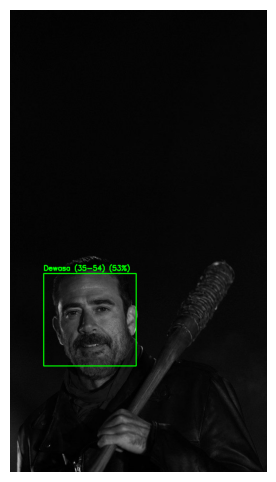

In [ ]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def predict_image(img_bgr, model=best_model):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.2, 5, minSize=(60, 60))
    if len(faces) == 0:                      # kalau wajah tak terdeteksi, pakai seluruh gambar
        h, w = img_bgr.shape[:2]; faces = [(0, 0, w, h)]
    for (x, y, w, h) in faces:
        face = cv2.cvtColor(img_bgr[y:y+h, x:x+w], cv2.COLOR_BGR2RGB)
        face = cv2.resize(face, (IMG, IMG)).astype('float32')
        p = model.predict(face[None], verbose=0)[0]
        text = f"{class_names[p.argmax()]} ({p.max()*100:.0f}%)"
        cv2.rectangle(img_bgr, (x, y), (x+w, y+h), (0, 255, 0), 2)
        cv2.putText(img_bgr, text, (x, max(y-8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        print("Hasil klasifikasi:", text)
    return img_bgr

from google.colab import files
up = files.upload()
for fn in up:
    im = cv2.imread(fn)
    plt.figure(figsize=(6, 6)); plt.imshow(cv2.cvtColor(predict_image(im), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

### 6.2 Webcam → Klik *Capture* → Muncul Prediksi Kelompok Usia
Browser akan meminta izin kamera (klik *Allow*).

<IPython.core.display.Javascript object>

Hasil klasifikasi: Remaja (13-19) (80%)


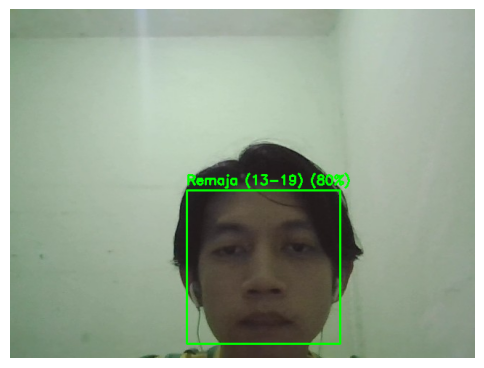

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='webcam.jpg', quality=0.9):
    js = Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """)
    display(js)
    data = eval_js(f'takePhoto({quality})')
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

fn = take_photo()
im = cv2.imread(fn)
plt.figure(figsize=(6, 6)); plt.imshow(cv2.cvtColor(predict_image(im), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

## 7. Hasil & Diskusi (isi sendiri setelah training selesai)
- Bandingkan Accuracy, F1-macro, dan Acc ±1 kelompok dari tabel 4.2
- Kelompok usia mana yang paling sering salah? (lihat Confusion Matrix, biasanya kelompok bersebelahan)
- Saran: pakai regresi umur (MAE), resolusi gambar lebih besar, dataset tambahan (IMDB-WIKI/AgeDB), EfficientNet/ViT

## 8. Reference
- UTKFace: https://susanqq.github.io/UTKFace/
- Dataset Kaggle: https://www.kaggle.com/datasets/jangedoo/utkface-new
- Krizhevsky et al. (2012) AlexNet; Simonyan & Zisserman (2014) VGG; Szegedy et al. (2015) GoogLeNet; He et al. (2016) ResNet